In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import os
os.environ["PATH"] = "/global/common/software/nersc9/texlive/2024/bin/x86_64-linux:" + os.environ["PATH"]

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = "Times New Roman"

import healpy as hp
import pollux
import pyccl
import scipy.stats
from tqdm.auto import trange

import pickle
import sacc

import re


In [3]:
sim_relative_path = "HACC150_3"
snap_sub_every_n = 2
seed = 0
nside = 8192
sim_root = "/pscratch/sd/d/desc/HOS_Sims/"
save_dir_root = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")


In [4]:
dndz_flag="SRDv1_nz"

kappa_dir=dndz_flag
if kappa_dir=="Euclid_dndz_fu08_bin1-5":
    kappa_dir="kappa_"+kappa_dir

reader_dict = dict(
    path=os.path.join(sim_root, sim_relative_path),
    run_params="run/indat.params",
    snap_sub_every_n=snap_sub_every_n,
)
reader = pollux.reader.HACCReader(**reader_dict)
reader_halo = pollux.reader.HACCHaloReader(halo_path="analysis/Halos/b0168/Props", **reader_dict)
cosmo_halofit = reader.cosmo

densitymax_z=1.5

builder_dict = dict(
    nside=nside,
    save_dir=os.path.join(
        save_dir_root,
        sim_relative_path,
        f"shells_z{reader.nsnapshots}_subsampledensitymax"+str(densitymax_z)+"_nside"+str(nside)+"/",
    ),
    apply_grid_isometry=True,
    seed=seed,
    subsample_box={"densitymax_z": densitymax_z},
    group_isometries=True,
    dtype=np.float32,
    wsp_dir=save_dir_root,
)

if os.path.exists(builder_dict["save_dir"]+"shell_hacc_seed"+str(seed)+"_shell_info.npy"):
    os.remove(builder_dict["save_dir"]+"shell_hacc_seed"+str(seed)+"_shell_info.npy")

builder = pollux.shells.SnapshotShellBuilder(reader, **builder_dict)
builder_halo = pollux.shells.SnapshotShellBuilder(reader_halo, **builder_dict)

if dndz_flag=="SRDv1_nz":
    dndz = np.loadtxt("data/"+dndz_flag+".txt")
else:
    dndz = np.loadtxt("data/"+dndz_flag+".dat")

lensing_dict_srd = dict(
    nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 6)],
    kappa_dir=kappa_dir,
    wsp_dir=save_dir_root,
    sigma_e=0.3,
)
lensing = pollux.lensing.BornLensingBuilder(builder, **lensing_dict_srd)

Cls_th_halofit = lensing.predict_cls(auto_only=False,error_bars=True,stacked=True)

# Without sigma_e

lensing_dict_srd_nosigmae = dict(
    nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 6)],
    kappa_dir=kappa_dir,
    wsp_dir=save_dir_root,
    sigma_e=0,
)
lensing_nosigmae = pollux.lensing.BornLensingBuilder(builder, **lensing_dict_srd_nosigmae)

Cls_th_halofit_nosigmae = lensing_nosigmae.predict_cls(auto_only=False,error_bars=True,stacked=True)


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x420ba374072ce6fb
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 2 snapshots, returns 51 snapshots
*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff   

[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

*** Map builder (kappa_hacc_seed0) ***
  - Number of maps = 5
  - Maps saved to /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/HACC150_3/shells_z51_subsampledensitymax1.5_nside8192/SRDv1_nz
Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

In [5]:
k = np.geomspace(1e-5, 1e3, 400)
h = cosmo_halofit["h"]
kh = k / h
z = np.linspace(10, 0, 100)

wsp = builder.get_cls_wsp()
bpws = wsp.get_bandpower_windows()[0, :, 0, :]

# 1. Evolution within shells

lk = np.log(k)

# Compute the C_ell

Cls_th_halofit_binned = {}

Cls_th_halofit_binned[0] = builder.get_cls_b().get_effective_ells()
Cls_th_halofit_binned[1] = {}
Cls_th_halofit_binned[2] = Cls_th_halofit[2]
Cls_th_halofit_binned[3] = Cls_th_halofit[3]

Cls_density_th_halofit_binned = {}
for ishell, t in enumerate(builder.get_tracers()):
    Cls_density_th_halofit_binned[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_halofit, t, t, np.arange(3 * nside), limber_max_error=0.001))#, p_of_k_a=pk_nonlin_halofit_binned_2D))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_halofit_binned[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_halofit_binned[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)

# 2. Cst within shells

Cls_th_halofit_binned_cst = {}

Cls_th_halofit_binned_cst[0] = builder.get_cls_b().get_effective_ells()
Cls_th_halofit_binned_cst[1] = {}
Cls_th_halofit_binned_cst[2] = Cls_th_halofit[2]
Cls_th_halofit_binned_cst[3] = Cls_th_halofit[3]

Cls_density_th_halofit_binned_cst = {}
for ishell, t in enumerate(builder.get_tracers()):
    # Create constant P(k,z) at P(k,zsnapshot)
    pk = cosmo_halofit.nonlin_matter_power(k, 1.0 / (1.0 + reader.zsnapshots[ishell]))
    pk_cst = pyccl.pk2d.Pk2D(a_arr=1/(1+z), lk_arr=lk, pk_arr=np.array([pk] * len(z)), is_logp=False)
    Cls_density_th_halofit_binned_cst[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_halofit, t, t, np.arange(3 * nside), limber_max_error=0.001, p_of_k_a=pk_cst))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_halofit_binned_cst[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_halofit_binned_cst[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)


Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


In [6]:
dndz_flag="SRDv1_nz"

kappa_dir=dndz_flag
if kappa_dir=="Euclid_dndz_fu08_bin1-5":
    kappa_dir="kappa_"+kappa_dir

reader_dict = dict(
    path=os.path.join(sim_root, sim_relative_path),
    run_params="run/indat.params",
    snap_sub_every_n=snap_sub_every_n,
    matter_power_spectrum=pyccl.CosmicemuMTIVPk(),
)
reader = pollux.reader.HACCReader(**reader_dict)
reader_halo = pollux.reader.HACCHaloReader(halo_path="analysis/Halos/b0168/Props", **reader_dict)
cosmo_MTIV = reader.cosmo

densitymax_z=1.5

builder_dict = dict(
    nside=nside,
    save_dir=os.path.join(
        save_dir_root,
        sim_relative_path,
        f"shells_z{reader.nsnapshots}_subsampledensitymax"+str(densitymax_z)+"_nside"+str(nside)+"/",
    ),
    apply_grid_isometry=True,
    seed=seed,
    subsample_box={"densitymax_z": densitymax_z},
    group_isometries=True,
    dtype=np.float32,
    wsp_dir=save_dir_root,
)

if os.path.exists(builder_dict["save_dir"]+"shell_hacc_seed"+str(seed)+"_shell_info.npy"):
    os.remove(builder_dict["save_dir"]+"shell_hacc_seed"+str(seed)+"_shell_info.npy")

builder = pollux.shells.SnapshotShellBuilder(reader, **builder_dict)
builder_halo = pollux.shells.SnapshotShellBuilder(reader_halo, **builder_dict)

if dndz_flag=="SRDv1_nz":
    dndz = np.loadtxt("data/"+dndz_flag+".txt")
else:
    dndz = np.loadtxt("data/"+dndz_flag+".dat")

lensing_dict_srd = dict(
    nzs=[(dndz[:, 0], dndz[:, i]) for i in range(1, 6)],
    kappa_dir=kappa_dir,
    wsp_dir=save_dir_root,
    sigma_e=0.3,
)
lensing = pollux.lensing.BornLensingBuilder(builder, **lensing_dict_srd)

Cls_th_MTIV = lensing.predict_cls(auto_only=False,error_bars=True,stacked=True)


*** HACC reader ***
  - Reading parameter file at /pscratch/sd/d/desc/HOS_Sims/HACC150_3/run/indat.params
  - Cosmology <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	matter_power_spectrum = <pyccl.emulators.cosmicemu_pk.CosmicemuMTIVPk object at 0x7f2e1b2b4390>
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x420ba374072ce6fb
  - Found 101 snapshots : [ 99 103 107 111 115 119 123 127 131 135 139 143 147 151 155 159 163 167
 171 175 179 183 187 191 195 199 203 207 211 215 219 223 227 231 235 239
 243 247 251 255 259 263 267 271 275 279 283 287 291 295 299 303 307 311
 315 319 323 327 331 335 339 343 347 351 355 359 363 367 371 375 379 383
 387 391 395 399 403 407 411 415 419 423 427 431 435 439 443 447 451 455
 459 463 467 471 475 479 483 487 491 495 499]
  - Subsampling : keeping every 2 snapshots, returns 51 snapshots
*** HACC reader ***
  - Reading parameter file at /pscratch

/global/u1/j/jmena/pollux_root/pollux/pollux/shells.py:277: UserWarning: Cannot write cosmo yaml file, likely due to using non-serializable options (eg P(k)).
  warnings.warn("Cannot write cosmo yaml file, likely due to using non-serializable options (eg P(k)).")


Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


[predict_cls]:   0%|          | 0/15 [00:00<?, ?it/s]

In [7]:
k = np.geomspace(1e-5, 1e3, 400)
h = cosmo_MTIV["h"]
kh = k / h
z = np.linspace(10, 0, 100)

wsp = builder.get_cls_wsp()
bpws = wsp.get_bandpower_windows()[0, :, 0, :]

# 1. Evolution within shells

lk = np.log(k)

Cls_th_MTIV_binned = {}

Cls_th_MTIV_binned[0] = builder.get_cls_b().get_effective_ells()
Cls_th_MTIV_binned[1] = {}
Cls_th_MTIV_binned[2] = Cls_th_halofit[2]
Cls_th_MTIV_binned[3] = Cls_th_halofit[3]

Cls_density_th_MTIV_binned = {}
for ishell, t in enumerate(builder.get_tracers()):
    Cls_density_th_MTIV_binned[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_MTIV, t, t, np.arange(3 * nside), limber_max_error=0.001))#, p_of_k_a=pk_nonlin_MTIV_binned_2D))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_MTIV_binned[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_MTIV_binned[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)
        
# 2. Cst within shells

Cls_th_MTIV_binned_cst = {}

Cls_th_MTIV_binned_cst[0] = builder.get_cls_b().get_effective_ells()
Cls_th_MTIV_binned_cst[1] = {}
Cls_th_MTIV_binned_cst[2] = Cls_th_halofit[2]
Cls_th_MTIV_binned_cst[3] = Cls_th_halofit[3]

Cls_density_th_MTIV_binned_cst = {}
for ishell, t in enumerate(builder.get_tracers()):
    # Create constant P(k,z) at P(k,zsnapshot)
    pk = cosmo_MTIV.nonlin_matter_power(k, 1.0 / (1.0 + reader.zsnapshots[ishell]))
    pk_cst = pyccl.pk2d.Pk2D(a_arr=1/(1+z), lk_arr=lk, pk_arr=np.array([pk] * len(z)), is_logp=False)
    Cls_density_th_MTIV_binned_cst[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_MTIV, t, t, np.arange(3 * nside), limber_max_error=0.001, p_of_k_a=pk_cst))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_MTIV_binned_cst[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_MTIV_binned_cst[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)
        

Loading workspace in /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/wsp_nside8192.wsp


In [8]:
import euclidemu2 as EE2

emulator = EE2.PyEuclidEmulator()

# Define the cosmological parameters

cosmo_EE2={'As': 2.16e-09,
           'ns': cosmo_halofit["n_s"],
           'Omb': cosmo_halofit["Omega_b"],
           'Omm': cosmo_halofit["Omega_b"] + cosmo_halofit["Omega_c"],
           'h': cosmo_halofit["h"],
           'mnu': 0,
           'w': -1.0,
           'wa': 0.0}

k = np.geomspace(1e-5, 1e3, 400)
h = cosmo_halofit["h"]
kh = k / h
z = np.linspace(10, 0, 100)

wsp = builder.get_cls_wsp()
bpws = wsp.get_bandpower_windows()[0, :, 0, :]

# 1. Evolution within shells

pk_nonlin_EE2 = emulator.get_pnonlin(emu_pars_dict=cosmo_EE2, redshifts=z, custom_kvec=kh)[1]

# Create the pyccl 2D p(k) instance

lk = np.log(k)

pk_arr = np.column_stack([pk_nonlin_EE2[zbin]/h**3 for zbin in range(len(z))]).T
pk_nonlin_EE2_binned_2D = pyccl.pk2d.Pk2D(a_arr=1/(1+z), lk_arr=lk, pk_arr=pk_arr, is_logp=False)

Cls_th_EE2_binned = {}

Cls_th_EE2_binned[0] = builder.get_cls_b().get_effective_ells()
Cls_th_EE2_binned[1] = {}
Cls_th_EE2_binned[2] = Cls_th_halofit[2]
Cls_th_EE2_binned[3] = Cls_th_halofit[3]

Cls_density_th_EE2_binned = {}
for ishell, t in enumerate(builder.get_tracers()):
    Cls_density_th_EE2_binned[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_halofit, t, t, np.arange(3 * nside), limber_max_error=0.001, p_of_k_a=pk_nonlin_EE2_binned_2D))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_EE2_binned[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_EE2_binned[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)

# 2. Cst within shells

z_shells = np.array([reader.zsnapshots[ishell] for ishell in range(builder.nshells)])[::-1]

pk_nonlin_EE2 = emulator.get_pnonlin(emu_pars_dict=cosmo_EE2, redshifts=z_shells, custom_kvec=kh)[1]

Cls_th_EE2_binned_cst = {}

Cls_th_EE2_binned_cst[0] = builder.get_cls_b().get_effective_ells()
Cls_th_EE2_binned_cst[1] = {}
Cls_th_EE2_binned_cst[2] = Cls_th_halofit[2]
Cls_th_EE2_binned_cst[3] = Cls_th_halofit[3]

Cls_density_th_EE2_binned_cst = {}
for ishell, t in enumerate(builder.get_tracers()):
    # Create constant P(k,z) at P(k,zsnapshot)
    pk = pk_nonlin_EE2[len(z_shells) - 1 - ishell]/h**3
    pk_cst = pyccl.pk2d.Pk2D(a_arr=1/(1+z), lk_arr=lk, pk_arr=np.array([pk] * len(z)), is_logp=False)
    Cls_density_th_EE2_binned_cst[ishell, ishell] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_halofit, t, t, np.arange(3 * nside), limber_max_error=0.001, p_of_k_a=pk_cst))

for i in range(lensing.nmaps):
    for j in range(lensing.nmaps):
        Cls_th_EE2_binned_cst[1][i, j] = np.sum(
            [lensing.compute_weight(ishell, i) * lensing.compute_weight(ishell, j) * Cls_density_th_EE2_binned_cst[ishell, ishell] for ishell in range(builder.nmaps)],
            axis=0)

# 3. Cls full

Cls_th_EE2 = {}

Cls_th_EE2[0] = builder.get_cls_b().get_effective_ells()
Cls_th_EE2[1] = {}
Cls_th_EE2[2] = Cls_th_halofit[2]
Cls_th_EE2[3] = Cls_th_halofit[3]

for ikappa_1, t_1 in enumerate(lensing.get_tracers()):
    for ikappa_2, t_2 in enumerate(lensing.get_tracers()):
        Cls_th_EE2[1][ikappa_1, ikappa_2] = np.dot(bpws, hp.pixwin(nside)**2 * pyccl.angular_cl(cosmo_halofit, t_1, t_2, np.arange(3 * nside), limber_max_error=0.001, p_of_k_a=pk_nonlin_EE2_binned_2D))


EuclidEmulator2 emulates the non-linear correction in 
the interval [8.73e-3 h/Mpc, 9.41h/Mpc]. You are 
requesting k modes beyond k_max = 9.41h/Mpc. 
Higher k modes constantly extrapolated.
EuclidEmulator2 emulates the non-linear correction in 
the interval [8.73e-3 h/Mpc, 9.41h/Mpc]. You are 
requesting k modes below k_min = 8.73e-3 h/Mpc. 
Lower k modes constantly extrapolated.
EuclidEmulator2 emulates the non-linear correction in 
the interval [8.73e-3 h/Mpc, 9.41h/Mpc]. You are 
requesting k modes beyond k_max = 9.41h/Mpc. 
Higher k modes constantly extrapolated.
EuclidEmulator2 emulates the non-linear correction in 
the interval [8.73e-3 h/Mpc, 9.41h/Mpc]. You are 
requesting k modes below k_min = 8.73e-3 h/Mpc. 
Lower k modes constantly extrapolated.


In [10]:
# Load the Cls from the sims
with open("data/Cls_dict_wshotnoise.pkl", "rb") as f:
    Cls_sims_dict = pickle.load(f)


In [11]:
def average_z(zbin):

    return np.trapz(lensing.nzs[zbin][0]*lensing.nzs[zbin][1], lensing.nzs[zbin][0])

def ell_min(zbin):
    
    theta_max = reader.boxsize()/cosmo_halofit.comoving_angular_distance(1/(1+average_z(zbin)))
    
    return np.pi/theta_max

ell_min_dict = {zbin: ell_min(zbin) for zbin in range(5)}


In [12]:
def average_z(zbin):

    return np.trapz(lensing.nzs[zbin][0]*lensing.nzs[zbin][1], lensing.nzs[zbin][0])

kmax = 5

ell_max_dict = {zbin: kmax * cosmo_halofit.comoving_radial_distance(1/(1+average_z(zbin))) for zbin in range(5)}


In [13]:
Cls_combined = {}

Cls_combined[r"{\tt HaloFit}"] = {}
Cls_combined[r"{\tt HaloFit} binned"] = {}
Cls_combined[r"{\tt HaloFit} binned cst"] = {}

Cls_combined["MTIV"] = {}
Cls_combined["MTIV binned"] = {}
Cls_combined["MTIV binned cst"] = {}

Cls_combined["EE2"] = {}
Cls_combined["EE2 binned"] = {}
Cls_combined["EE2 binned cst"] = {}

for keyword in Cls_th_halofit[1].keys():
    Cls_combined[r"{\tt HaloFit}"][f"{keyword}"] = np.column_stack([Cls_th_halofit[0], Cls_th_halofit[1][keyword]])
    Cls_combined[r"{\tt HaloFit} binned"][f"{keyword}"] = np.column_stack([Cls_th_halofit_binned[0], Cls_th_halofit_binned[1][keyword]])
    Cls_combined[r"{\tt HaloFit} binned cst"][f"{keyword}"] = np.column_stack([Cls_th_halofit_binned_cst[0], Cls_th_halofit_binned_cst[1][keyword]])
    
    Cls_combined["MTIV"][f"{keyword}"] = np.column_stack([Cls_th_MTIV[0], Cls_th_MTIV[1][keyword]])
    Cls_combined["MTIV binned"][f"{keyword}"] = np.column_stack([Cls_th_MTIV_binned[0], Cls_th_MTIV_binned[1][keyword]])
    Cls_combined["MTIV binned cst"][f"{keyword}"] = np.column_stack([Cls_th_MTIV_binned_cst[0], Cls_th_MTIV_binned_cst[1][keyword]])
    
    Cls_combined["EE2"][f"{keyword}"] = np.column_stack([Cls_th_EE2[0], Cls_th_EE2[1][keyword]])
    Cls_combined["EE2 binned"][f"{keyword}"] = np.column_stack([Cls_th_EE2_binned[0], Cls_th_EE2_binned[1][keyword]])
    Cls_combined["EE2 binned cst"][f"{keyword}"] = np.column_stack([Cls_th_EE2_binned_cst[0], Cls_th_EE2_binned_cst[1][keyword]])
    
Cls_combined["Sims avg."] = Cls_sims_dict[(2048, "avg", "avg", builder.nmaps, "method\\ (1)")]
Cls_combined["Sims std."] = Cls_sims_dict[(2048, "std", "std", builder.nmaps, "method\\ (1)")]
    

In [14]:
list_plot = [
    # r"{\tt HaloFit}",
    # r"{\tt HaloFit} binned",
    # r"{\tt HaloFit} binned cst",
    
    "MTIV",
    # "MTIV binned",
    # "MTIV binned cst",
    
    # "Bacco",
    # "Bacco binned",
    # "Bacco binned cst",

    "EE2",
    # "EE2 binned",
    # "EE2 binned cst",
    
    # "pk sims",
    
    "Sims avg.",
]


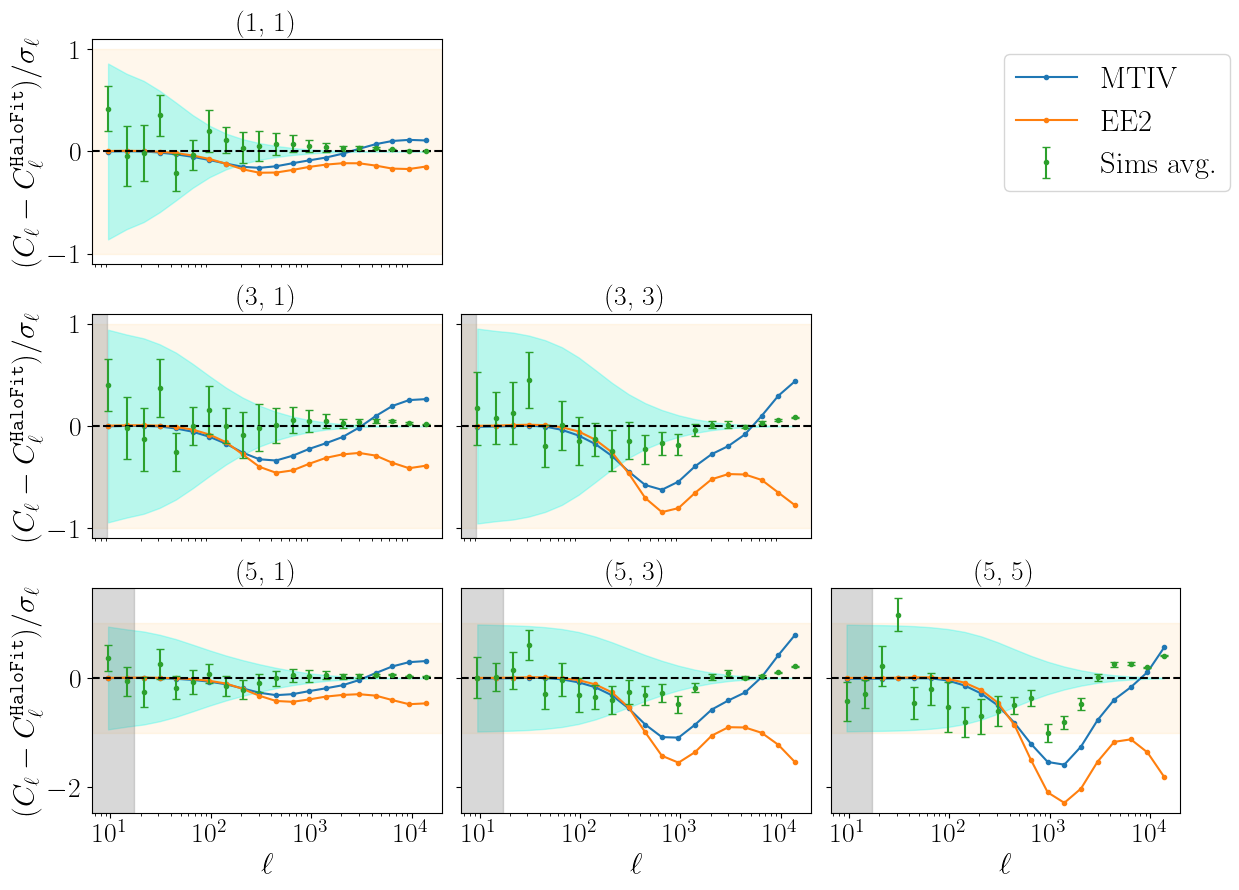

In [15]:
map_list = np.arange(0, 5)
map_list = [0, 2, 4]

from plots_methods import plot_Cls_kappa

Cls_th = Cls_th_halofit
Cls_th_nosigmae = Cls_th_halofit_nosigmae

# Plot 3
plot_Cls_kappa(3, map_list, Cls_combined, Cls_th, ell_min_dict, list_plot, Cls_th_nosigmae=Cls_th_nosigmae, use_keys_for_labels=True, ylabel=r"$(C_\ell-C_\ell^{\tt HaloFit})/\sigma_\ell$")
